In [1]:
# ============================================================
# 1. IMPORT LIBRARY
# Fungsi: Memanggil library yang dibutuhkan untuk pengolahan data.
# Manfaat: Mempermudah analisis, visualisasi, dan pembuatan model.
# ============================================================

import pandas as pd                 # Mengolah data berbentuk tabel.
import numpy as np                  # Melakukan operasi numerik.
import matplotlib.pyplot as plt     # Membuat grafik.
import seaborn as sns               # Membuat visualisasi statistik.

# ============================================================
# 2. DATA LOADING
# Fungsi: Membaca dataset esports dan kamus data dari file CSV.
# Manfaat: Memasukkan data ke Python agar dapat dianalisis.
# ============================================================

df = pd.read_csv("esports_gaming_biometrics_250k.csv")
dictionary = pd.read_csv("data_dictionary.csv")

# Menampilkan lima baris pertama untuk melihat contoh data.
print("Lima Data Teratas:")
print(df.head())

# Menampilkan jumlah baris dan kolom.
# Manfaat: Mengetahui ukuran dataset yang sedang digunakan.
print("\nUkuran Dataset:", df.shape)

# Menampilkan tipe data dan informasi setiap kolom.
# Manfaat: Mengetahui apakah data sudah sesuai dengan kebutuhan.
df.info()

# Menampilkan penjelasan kolom dari data dictionary.
# Manfaat: Memahami arti setiap atribut dalam dataset.
print("\nData Dictionary:")
print(dictionary.head())

Lima Data Teratas:
   Player_ID  Age     Game_Genre  PlayTime_Hours  Sleep_Hours  Energy_Drinks  \
0  PL_000001   24            FPS            1.41         8.88              0   
1  PL_000002   22            FPS            4.43         7.45              2   
2  PL_000003   25  Battle Royale            3.75         8.10              1   
3  PL_000004   29            FPS            1.76         6.69              0   
4  PL_000005   22            FPS            5.79         8.17              1   

   Screen_Brightness Blue_Light_Filter  APM  Heart_Rate_BPM  HRV_Score  \
0               43.4               Yes  107              78      95.02   
1               88.0               Yes  110             102      82.92   
2               24.8               Yes  152              96      89.13   
3               80.2                No  151              65      80.41   
4               34.4                No  148              95      95.71   

   Reaction_Time_ms Match_Outcome  
0            268.96

In [2]:
# ============================================================
# 3. DATA CLEANING
# Fungsi: Membersihkan data agar lebih konsisten dan layak dianalisis.
# Manfaat: Mengurangi kesalahan yang dapat mengganggu hasil analisis.
# ============================================================

# Menghapus spasi yang tidak diperlukan pada nama kolom.
# Manfaat: Mencegah kesalahan ketika memanggil nama kolom.
df.columns = df.columns.str.strip()

# Menghapus baris yang memiliki data duplikat.
# Manfaat: Menghindari penghitungan data yang sama berulang kali.
df = df.drop_duplicates().copy()

# Mengubah teks kosong menjadi nilai NaN.
# Manfaat: Membantu Python mengenali data yang tidak tersedia.
df = df.replace(r"^\s*$", np.nan, regex=True)

# Menghapus kolom yang seluruh nilainya kosong.
# Manfaat: Menghilangkan kolom yang tidak memberikan informasi.
df = df.dropna(axis=1, how="all")

# Memastikan kolom target tersedia.
# Match_Outcome akan digunakan untuk memprediksi hasil pertandingan.
target = "Match_Outcome"

if target not in df.columns:
    raise ValueError("Kolom Match_Outcome tidak ditemukan!")

# Menghapus baris yang tidak memiliki target.
# Manfaat: Model membutuhkan label hasil untuk belajar.
df = df.dropna(subset=[target]).copy()

# Menghapus spasi berlebih pada data berbentuk teks.
# Manfaat: Mencegah kategori yang sama dianggap berbeda.
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].str.strip()

# Menampilkan jumlah nilai kosong setiap kolom.
# Manfaat: Menentukan kolom yang membutuhkan penanganan missing value.
print("\nMissing Value:")
print(df.isnull().sum())

# Menampilkan ukuran data setelah proses pembersihan.
print("\nUkuran Setelah Cleaning:", df.shape)


Missing Value:
Player_ID                0
Age                      0
Game_Genre               0
PlayTime_Hours           0
Sleep_Hours              0
Energy_Drinks            0
Screen_Brightness    12548
Blue_Light_Filter        0
APM                      0
Heart_Rate_BPM           0
HRV_Score             4934
Reaction_Time_ms         0
Match_Outcome            0
dtype: int64

Ukuran Setelah Cleaning: (250000, 13)


In [3]:
# ============================================================
# 4. DATA TRANSFORMATION
# Fungsi: Mengubah format data agar sesuai dengan kebutuhan analisis.
# Manfaat: Membantu proses preprocessing dan pelatihan model.
# ============================================================

# Menghapus Player_ID dari fitur jika kolom tersebut tersedia.
# Manfaat: ID biasanya hanya berfungsi sebagai identitas pemain.
df = df.drop(columns=["Player_ID"], errors="ignore")

# Menentukan kolom yang seharusnya memiliki nilai numerik.
# Manfaat: Memastikan angka tidak salah dibaca sebagai teks.
numeric_columns = [
    "Age",
    "PlayTime_Hours",
    "Sleep_Hours",
    "Energy_Drinks",
    "Screen_Brightness",
    "APM",
    "Heart_Rate_BPM",
    "HRV_Score",
    "Reaction_Time_ms"
]

# Mengubah kolom numerik ke tipe angka.
# Nilai yang tidak dapat diubah menjadi angka dijadikan NaN.
# Manfaat: Memungkinkan nilai tersebut ditangani pada preprocessing.
for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Memisahkan fitur (X) dan target (y).
# X berisi informasi pemain, sedangkan y berisi hasil pertandingan.
X = df.drop(columns=[target])
y = df[target].astype(str).str.strip()

# Menampilkan jumlah fitur dan target.
print("Ukuran Fitur:", X.shape)
print("Jumlah Target:", y.shape)

# Menampilkan jumlah data pada setiap kategori hasil pertandingan.
# Manfaat: Mengetahui apakah distribusi target seimbang.
print("\nDistribusi Match Outcome:")
print(y.value_counts())

Ukuran Fitur: (250000, 11)
Jumlah Target: (250000,)

Distribusi Match Outcome:
Match_Outcome
Loss    129844
Win     120156
Name: count, dtype: int64



Statistik Deskriptif:
                      count unique   top    freq        mean        std  \
Age                250000.0    NaN   NaN     NaN   22.588136   3.829706   
Game_Genre           250000      4  MOBA   99887         NaN        NaN   
PlayTime_Hours     250000.0    NaN   NaN     NaN    2.527753   2.358799   
Sleep_Hours        250000.0    NaN   NaN     NaN      6.5009   1.495851   
Energy_Drinks      250000.0    NaN   NaN     NaN     0.91772   1.045559   
Screen_Brightness  237452.0    NaN   NaN     NaN   54.918735  25.965989   
Blue_Light_Filter    250000      2    No  162320         NaN        NaN   
APM                250000.0    NaN   NaN     NaN  204.076168  77.004233   
Heart_Rate_BPM     250000.0    NaN   NaN     NaN   84.062784   9.670229   
HRV_Score          245066.0    NaN   NaN     NaN   87.479087  11.063101   
Reaction_Time_ms   250000.0    NaN   NaN     NaN  262.900538  19.096927   
Match_Outcome        250000      2  Loss  129844         NaN        NaN   

 

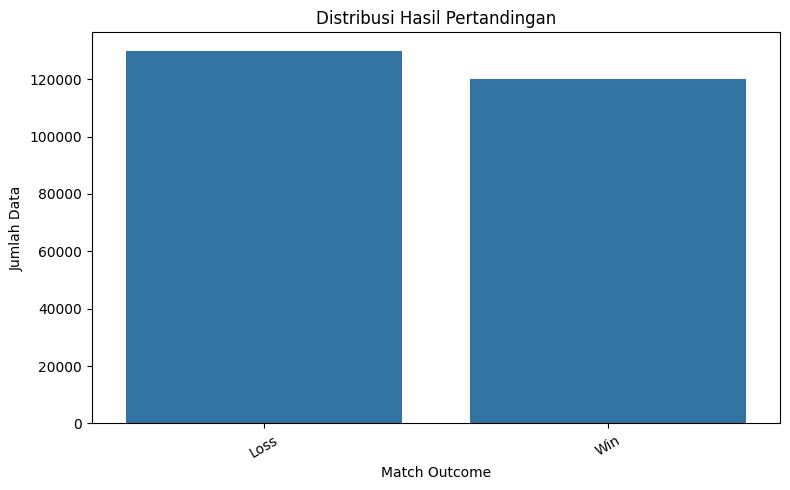

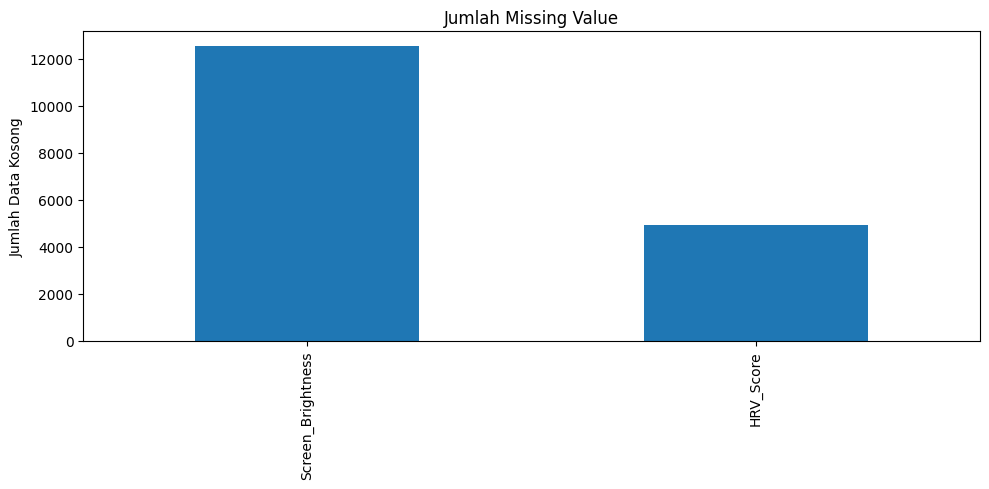

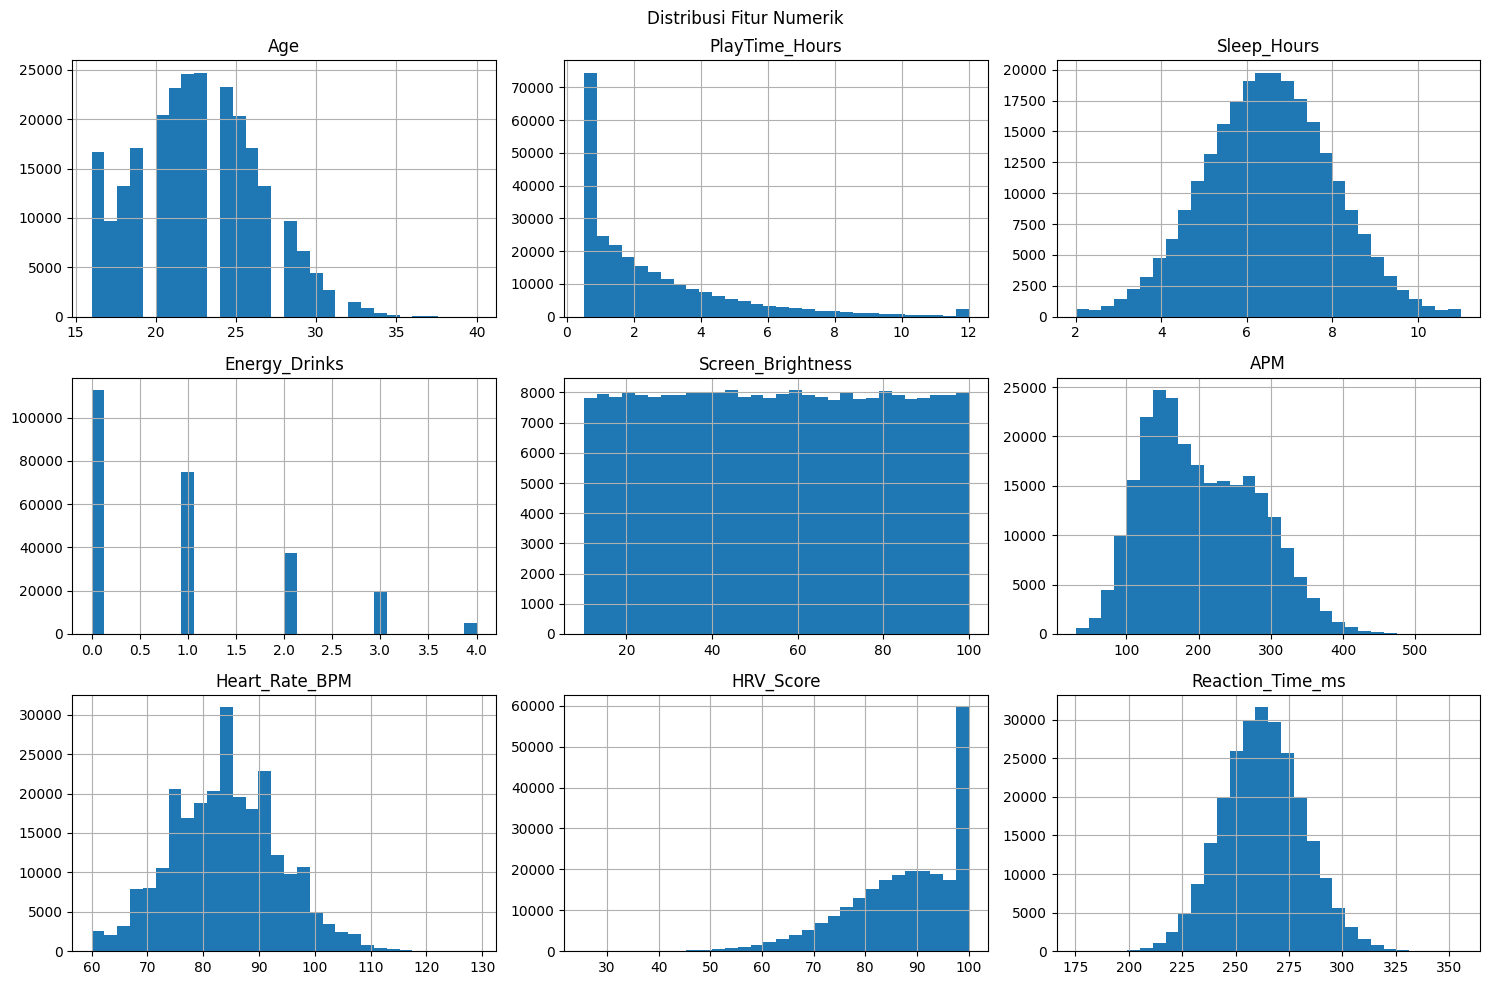

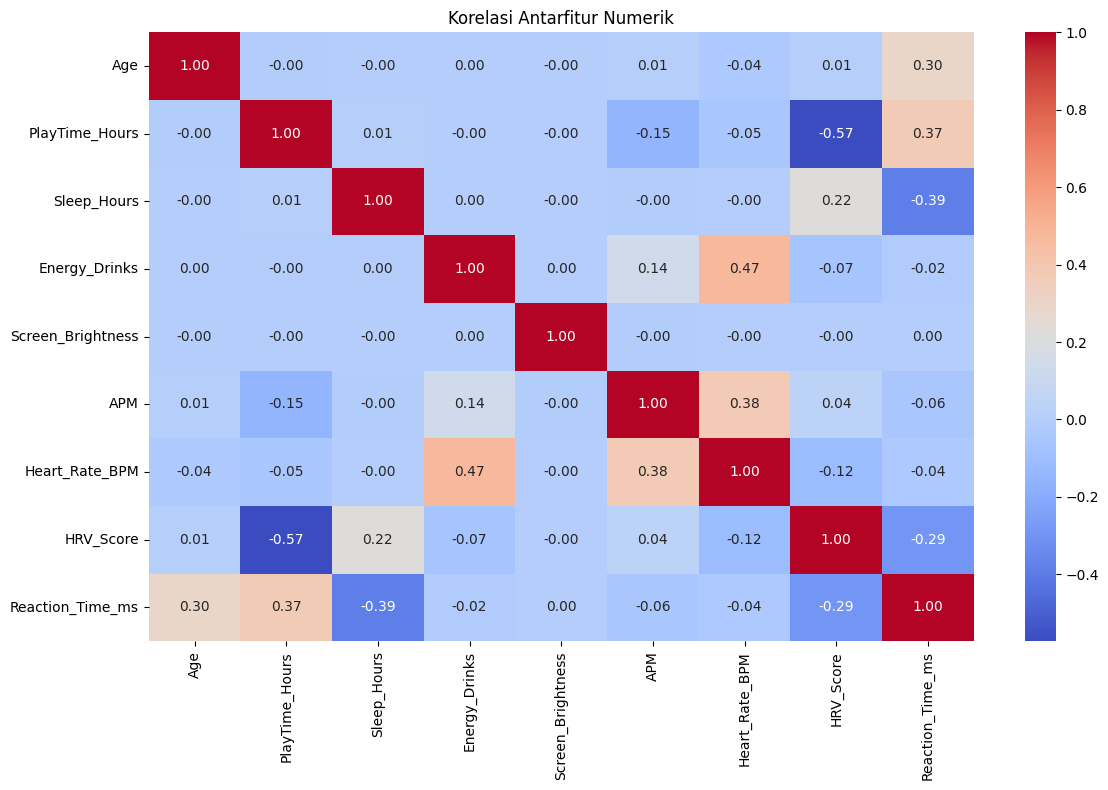

In [4]:
# ============================================================
# 5. EDA
# Fungsi: Mengeksplorasi karakteristik dan pola dasar dataset.
# Manfaat: Membantu memahami data sebelum membangun model.
# ============================================================

# Menampilkan statistik deskriptif seluruh kolom.
# Manfaat: Mengetahui rata-rata, sebaran, nilai minimum, dan maksimum.
print("\nStatistik Deskriptif:")
print(df.describe(include="all").T)

# Menghitung distribusi hasil pertandingan.
# Manfaat: Mengetahui kategori hasil yang paling banyak muncul.
print("\nDistribusi Hasil Pertandingan:")
print(y.value_counts())

# Membuat grafik jumlah data untuk setiap kategori target.
# Manfaat: Mempermudah pengamatan ketidakseimbangan kelas.
plt.figure(figsize=(8, 5))
sns.countplot(x=y, order=y.value_counts().index)
plt.title("Distribusi Hasil Pertandingan")
plt.xlabel("Match Outcome")
plt.ylabel("Jumlah Data")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Menghitung jumlah nilai kosong pada setiap kolom.
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

# Membuat grafik hanya jika terdapat nilai kosong.
# Manfaat: Mempermudah identifikasi kolom yang bermasalah.
if len(missing) > 0:
    missing.plot(kind="bar", figsize=(10, 5))
    plt.title("Jumlah Missing Value")
    plt.ylabel("Jumlah Data Kosong")
    plt.tight_layout()
    plt.show()
else:
    print("Tidak terdapat missing value.")

# Memilih kolom numerik untuk analisis distribusi.
numeric_df = df.select_dtypes(include=np.number)

# Membuat histogram setiap fitur numerik.
# Manfaat: Melihat pola sebaran data dan kemungkinan nilai ekstrem.
numeric_df.hist(figsize=(15, 10), bins=30)
plt.suptitle("Distribusi Fitur Numerik")
plt.tight_layout()
plt.show()

# Membuat heatmap korelasi antarfitur numerik.
# Manfaat: Mengetahui hubungan linear antarvariabel numerik.
if numeric_df.shape[1] >= 2:
    plt.figure(figsize=(12, 8))
    sns.heatmap(
        numeric_df.corr(),
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )
    plt.title("Korelasi Antarfitur Numerik")
    plt.tight_layout()
    plt.show()


Rata-rata Fitur Berdasarkan Hasil:
                 Age  PlayTime_Hours  Sleep_Hours  Energy_Drinks  \
Match_Outcome                                                      
Loss           22.65            2.59         6.47           0.91   
Win            22.52            2.46         6.53           0.93   

               Screen_Brightness     APM  Heart_Rate_BPM  HRV_Score  \
Match_Outcome                                                         
Loss                       54.84  200.43           83.88      87.29   
Win                        55.00  208.02           84.26      87.68   

               Reaction_Time_ms  
Match_Outcome                    
Loss                     263.94  
Win                      261.77  


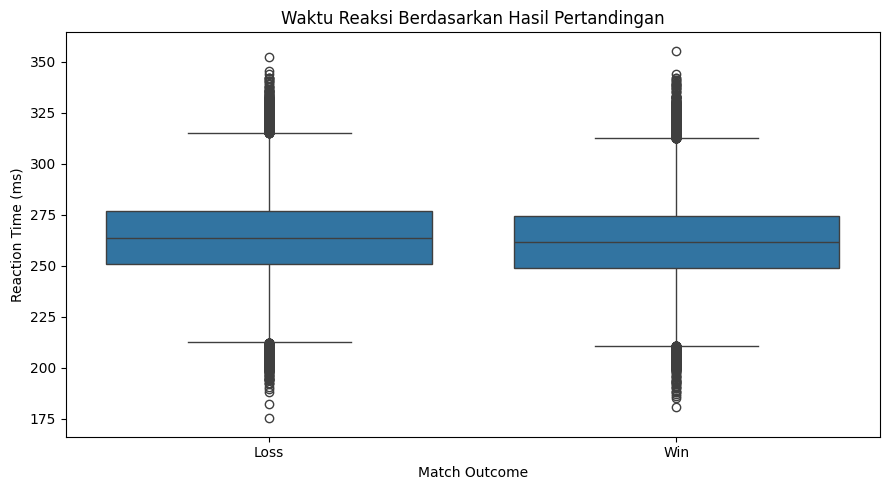

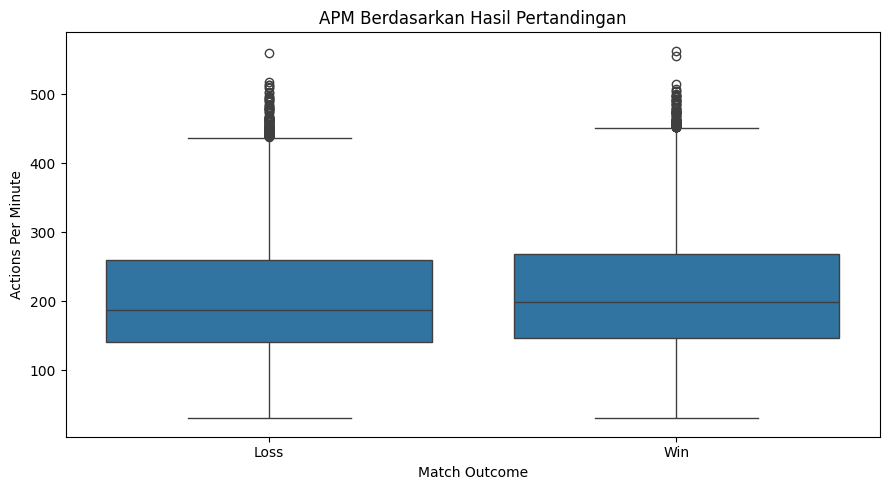

In [5]:
# ============================================================
# 6. EXDA
# Fungsi: Menganalisis hubungan karakteristik pemain dengan hasil.
# Manfaat: Membantu menemukan pola yang dapat diteliti lebih lanjut.
# ============================================================

# Membuat salinan data dan menyertakan kembali kolom target.
analysis_df = df.copy()
analysis_df[target] = y

# Memilih fitur numerik untuk dibandingkan.
numeric_cols = analysis_df.select_dtypes(
    include=np.number
).columns.tolist()

# Menghitung rata-rata fitur numerik untuk setiap hasil pertandingan.
# Manfaat: Membandingkan karakteristik rata-rata antarkategori.
if numeric_cols:
    outcome_analysis = analysis_df.groupby(target)[
        numeric_cols
    ].mean().round(2)

    print("\nRata-rata Fitur Berdasarkan Hasil:")
    print(outcome_analysis)

# Membandingkan waktu reaksi berdasarkan hasil pertandingan.
# Manfaat: Mengamati variasi waktu reaksi pada setiap kategori.
if "Reaction_Time_ms" in df.columns:
    plt.figure(figsize=(9, 5))
    sns.boxplot(
        data=analysis_df,
        x=target,
        y="Reaction_Time_ms"
    )
    plt.title("Waktu Reaksi Berdasarkan Hasil Pertandingan")
    plt.xlabel("Match Outcome")
    plt.ylabel("Reaction Time (ms)")
    plt.tight_layout()
    plt.show()

# Membandingkan APM berdasarkan hasil pertandingan.
# APM adalah Actions Per Minute.
# Manfaat: Mengamati perbedaan aktivitas pemain pada setiap kategori.
if "APM" in df.columns:
    plt.figure(figsize=(9, 5))
    sns.boxplot(
        data=analysis_df,
        x=target,
        y="APM"
    )
    plt.title("APM Berdasarkan Hasil Pertandingan")
    plt.xlabel("Match Outcome")
    plt.ylabel("Actions Per Minute")
    plt.tight_layout()
    plt.show()

In [6]:
# ============================================================
# 7. DATA SPLITTING
# Fungsi: Membagi dataset menjadi data training dan testing.
# Manfaat: Menguji kemampuan model pada data yang tidak dipakai belajar.
# ============================================================

from sklearn.model_selection import train_test_split

# Menentukan stratifikasi jika setiap kelas memiliki minimal dua data.
# Manfaat: Menjaga proporsi kategori target pada kedua bagian data.
stratify_target = y if y.value_counts().min() >= 2 else None

# Membagi data dengan rasio 80% training dan 20% testing.
# random_state=42 menjaga pembagian tetap sama ketika dijalankan ulang.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=stratify_target
)

# Menampilkan ukuran data hasil pembagian.
# Manfaat: Memastikan jumlah data training dan testing sesuai.
print("Data Training:", X_train.shape)
print("Data Testing:", X_test.shape)

# Menampilkan distribusi kategori target pada data training.
print("\nDistribusi Target Training:")
print(y_train.value_counts())

# Menampilkan distribusi kategori target pada data testing.
print("\nDistribusi Target Testing:")
print(y_test.value_counts())

Data Training: (200000, 11)
Data Testing: (50000, 11)

Distribusi Target Training:
Match_Outcome
Loss    103875
Win      96125
Name: count, dtype: int64

Distribusi Target Testing:
Match_Outcome
Loss    25969
Win     24031
Name: count, dtype: int64


In [7]:
# ============================================================
# 8. DATA PREPROCESSING
# Fungsi: Menangani missing value dan mengubah format fitur.
# Manfaat: Menyiapkan data agar dapat diproses algoritma ML.
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Memisahkan kolom numerik dari kolom kategorikal.
# Manfaat: Memungkinkan setiap jenis data diproses dengan cara berbeda.
num_cols = X_train.select_dtypes(
    include=np.number
).columns.tolist()

cat_cols = [
    col for col in X_train.columns
    if col not in num_cols
]

# Membuat alur preprocessing numerik.
# Median digunakan untuk mengisi nilai kosong.
# StandardScaler menyamakan skala fitur numerik.
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Membuat alur preprocessing kategorikal.
# Modus digunakan untuk mengisi nilai kosong.
# OneHotEncoder mengubah kategori menjadi representasi numerik.
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Menggabungkan proses numerik dan kategorikal.
# Manfaat: Seluruh fitur dapat diproses dalam satu alur otomatis.
preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

print("Preprocessing berhasil disiapkan.")

Preprocessing berhasil disiapkan.


In [8]:
# ============================================================
# 9. DATA MODELING
# Fungsi: Melatih beberapa algoritma untuk memprediksi hasil pertandingan.
# Manfaat: Membandingkan algoritma dan menentukan model yang paling baik.
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Menentukan tiga algoritma klasifikasi yang akan diuji.
# Logistic Regression: model klasifikasi sebagai pembanding awal.
# Decision Tree: mempelajari pola melalui aturan keputusan.
# Random Forest: menggabungkan banyak pohon keputusan.
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=15,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

# Menyediakan tempat untuk menyimpan pipeline model yang sudah dilatih.
# Manfaat: Model dapat digunakan kembali pada tahap evaluasi.
trained_models = {}

# Melatih setiap algoritma menggunakan data training.
for name, model in models.items():

    # Menggabungkan preprocessing dan algoritma dalam satu pipeline.
    # Manfaat: Preprocessing diterapkan secara konsisten pada setiap model.
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    # Mempelajari pola hubungan antara fitur dan target.
    pipeline.fit(X_train, y_train)

    # Menyimpan model yang telah dilatih.
    trained_models[name] = pipeline

    print(f"{name} berhasil dilatih.")

print("\nSemua model selesai dilatih.")

Logistic Regression berhasil dilatih.
Decision Tree berhasil dilatih.
Random Forest berhasil dilatih.

Semua model selesai dilatih.


In [9]:
# ============================================================
# 10. EVALUASI MODEL
# Fungsi: Mengukur kualitas prediksi setiap algoritma.
# Manfaat: Menentukan model yang paling sesuai berdasarkan hasil pengujian.
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Menyediakan daftar untuk menyimpan hasil evaluasi.
results = []

# Menguji seluruh model dengan data testing.
for name, model in trained_models.items():

    # Memprediksi hasil pertandingan berdasarkan fitur testing.
    y_pred = model.predict(X_test)

    # Menghitung metrik performa setiap model.
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision Macro": precision_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "Recall Macro": recall_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "F1 Macro": f1_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        )
    })

# Mengubah hasil evaluasi menjadi tabel.
results_df = pd.DataFrame(results)

# Mengurutkan model berdasarkan F1 Macro tertinggi.
# Manfaat: Membantu memilih model dengan performa antarkelas seimbang.
results_df = results_df.sort_values(
    by="F1 Macro",
    ascending=False
).reset_index(drop=True)

print("\nPerbandingan Hasil Evaluasi:")
print(results_df.round(4))

# Mengambil model dengan F1 Macro tertinggi.
best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]

# Membuat prediksi menggunakan model terbaik.
y_pred_best = best_model.predict(X_test)

# Menampilkan precision, recall, F1-score, dan support tiap kelas.
print("\nModel Terbaik:", best_name)
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_best,
    zero_division=0
))


Perbandingan Hasil Evaluasi:
                 Model  Accuracy  Precision Macro  Recall Macro  F1 Macro
0  Logistic Regression    0.5294           0.5291        0.5292    0.5291
1        Random Forest    0.5167           0.5161        0.5161    0.5161
2        Decision Tree    0.5138           0.5158        0.5157    0.5134

Model Terbaik: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

        Loss       0.55      0.54      0.54     25969
         Win       0.51      0.52      0.52     24031

    accuracy                           0.53     50000
   macro avg       0.53      0.53      0.53     50000
weighted avg       0.53      0.53      0.53     50000



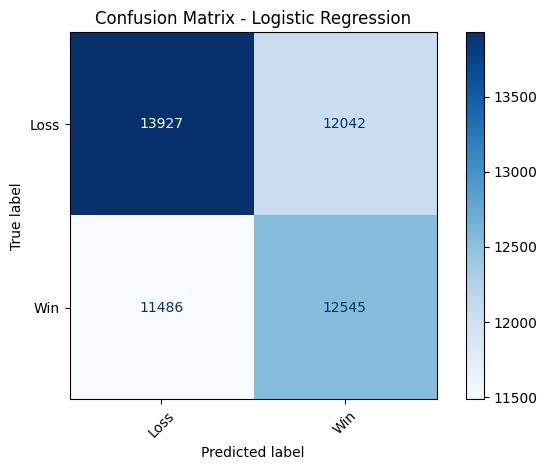

In [10]:
# ============================================================
# 11. CONFUSION MATRIX
# Fungsi: Memvisualisasikan hasil prediksi benar dan salah.
# Manfaat: Mengetahui kategori yang sering tertukar oleh model.
# ============================================================

from sklearn.metrics import ConfusionMatrixDisplay

# Membuat confusion matrix dari hasil prediksi model terbaik.
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_best,
    xticks_rotation=45,
    cmap="Blues"
)

# Memberikan judul pada grafik.
plt.title(f"Confusion Matrix - {best_name}")

# Merapikan tata letak grafik.
plt.tight_layout()

# Menampilkan grafik.
plt.show()

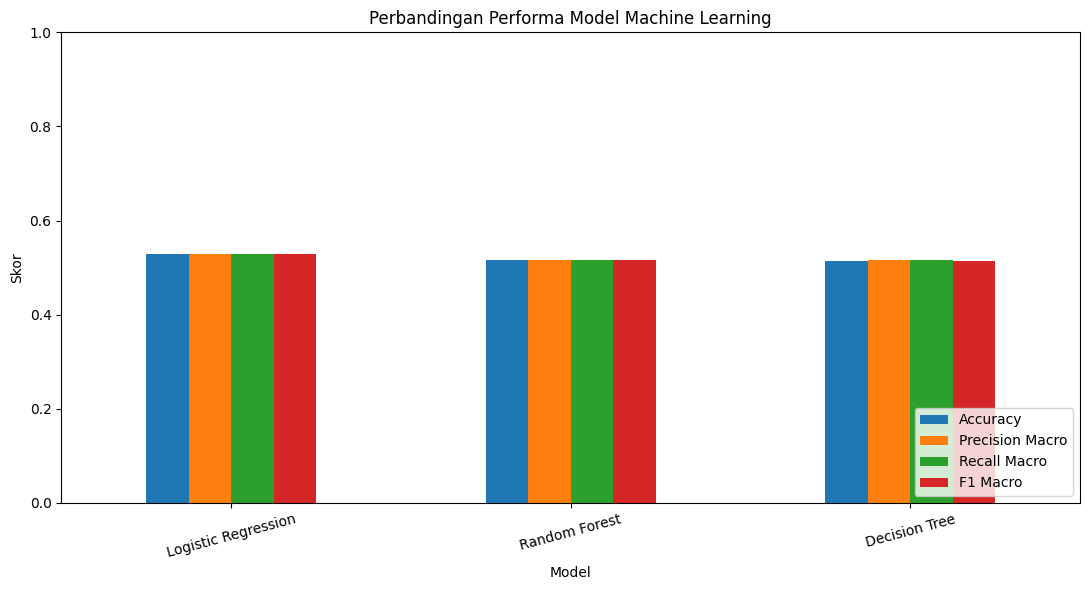

In [11]:
# ============================================================
# 12. PERBANDINGAN MODEL
# Fungsi: Menampilkan metrik evaluasi dalam bentuk grafik.
# Manfaat: Mempermudah perbandingan performa setiap algoritma.
# ============================================================

# Memilih kolom metrik yang akan dibandingkan.
results_plot = results_df.set_index("Model")[
    ["Accuracy", "Precision Macro", "Recall Macro", "F1 Macro"]
]

# Membuat grafik batang perbandingan metrik.
results_plot.plot(kind="bar", figsize=(11, 6))

# Memberikan judul dan label grafik.
plt.title("Perbandingan Performa Model Machine Learning")
plt.ylabel("Skor")

# Membatasi skor pada rentang 0 sampai 1.
plt.ylim(0, 1)

# Mengatur kemiringan nama model dan posisi legenda.
plt.xticks(rotation=15)
plt.legend(loc="lower right")

# Merapikan dan menampilkan grafik.
plt.tight_layout()
plt.show()

In [12]:
# ============================================================
# 13. MODEL SAVING
# Fungsi: Menyimpan model terbaik ke dalam file.
# Manfaat: Model dapat digunakan kembali tanpa pelatihan ulang.
# ============================================================

import joblib

# Menyimpan pipeline lengkap, termasuk preprocessing dan model.
joblib.dump(best_model, "model_esports_terbaik.pkl")

# Memberikan informasi bahwa proses penyimpanan selesai.
print("Model berhasil disimpan: model_esports_terbaik.pkl")

Model berhasil disimpan: model_esports_terbaik.pkl


In [13]:
# ============================================================
# 14. PREDIKSI DATA
# Fungsi: Mencoba model pada satu baris data testing.
# Manfaat: Memastikan model dapat menghasilkan prediksi.
# ============================================================

# Mengambil satu sampel dari data testing.
# Bentuk dua dimensi dipertahankan agar sesuai dengan input model.
data_baru = X_test.iloc[[0]]

# Menghasilkan prediksi hasil pertandingan.
prediksi = best_model.predict(data_baru)

# Menampilkan data yang digunakan untuk prediksi.
print("Data Pemain:")
print(data_baru)

# Menampilkan hasil prediksi dan label sebenarnya.
print("\nPrediksi Match Outcome:", prediksi[0])
print("Hasil Sebenarnya:", y_test.iloc[0])

Data Pemain:
        Age Game_Genre  PlayTime_Hours  Sleep_Hours  Energy_Drinks  \
132734   24        FPS             0.5         7.74              2   

        Screen_Brightness Blue_Light_Filter  APM  Heart_Rate_BPM  HRV_Score  \
132734               97.9               Yes  148              94      80.71   

        Reaction_Time_ms  
132734             248.6  

Prediksi Match Outcome: Win
Hasil Sebenarnya: Loss
